# [1] Problem

This project aims to analyze educational data to predict students' academic performance and understand their learning behaviors. Using various student attributes such as study hours, attendance, parental support, and GPA. the project applies classification techniques to predict each student's final grade class.

In addition, clustering methods are used to group students with similar habits and characteristics, helping to uncover hidden patterns and study profiles within the data. By combining these approaches, the project provides meaningful insights that help educators identify struggling students early and support data-driven decisions in education.

We chose this topic (predicting student performance) because education plays a vital role in students' futures, and early academic support can make a major difference in their success. By using classification techniques and clustering methods, we can identify students who need help during the semester rather than waiting until final exams.

Analyzing daily habits and academic factors helps schools provide targeted tutoring and advising where it is needed most. This project also shows how data mining techniques can be used practically to solve real-world challenges in education.

# [2] Data Mining Task

The goal of this project is to analyze students’ performance using data mining techniques. The project will focus on classification and clustering tasks. Classification will be used to predict students’ academic performance based on their characteristics, while clustering will be used to identify groups of students with similar characteristics.

# [3] Data

Phase 1 (Data Selection) introduces the dataset we selected, the Students Performance dataset from Kaggle. It contains 2,392 records (students) and 15 attributes. The attributes describe each student’s demographic information (Age, Gender, Ethnicity, ParentalEducation), study habits (StudyTimeWeekly, Absences, Tutoring), parental involvement (ParentalSupport), extracurricular activities (Extracurricular, Sports, Music, Volunteering) and academic performance (GPA). In Phase 1 we described the dataset source, the number of attributes, the data types, the number of records and the class attribute, GradeClass, which represents the student’s academic performance class (0–4). We also showed the class distribution, where class 4 is the largest (1,211 students) and class 0 is the smallest (107 students), and displayed a sample of the raw dataset.



##Dataset Source
Dataset Name: Students Performance

Dataset Source: Kaggle [1]

URL: https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset

##Dataset Description
###A. Number of Attributes
The dataset contains 15 attributes

###B. Data Types
The dataset contains 13 integer attributes (int64) and 2 floating-point attributes (float64).

###C. Number of Records
The dataset contains 2,392 records (students).

###D. Class Attribute
The class attribute is GradeClass. It represents the students' academic performance class.

###E. Class Distribution
The dataset contains five classes in the GradeClass attribute. The number of students in each class is shown below:
| GradeClass | Number of Students |
|------------|-------------------:|
| 0 | 107 |
| 1 | 269 |
| 2 | 391 |
| 3 | 414 |
| 4 | 1211

###F. Sample of Raw Dataset
The following table shows a sample of the raw dataset:



In [150]:
import pandas as pd
df = pd.read_csv("Raw_dataset.csv")
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


In [151]:
df.shape

(2392, 15)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   int64  
dtypes: float64(2), int64(13)
memory usage: 280.4 KB


In [10]:
df["GradeClass"].value_counts().sort_index()

,count
GradeClass,
0.0,107
1.0,269
2.0,391
3.0,414
4.0,1211


Phase 2 (Data Analysis) summarizes and visualizes the raw dataset to understand it before preprocessing. We first computed a statistical summary of the numerical attributes (Age, StudyTimeWeekly, Absences and GPA), including the mean, standard deviation and five-number summary. We then checked for missing values and found none. Box plots grouped by GradeClass showed outliers in Absences and GPA, while the Z-score method (threshold = 2) detected 46 outliers in GPA only. Histograms showed the distributions of StudyTimeWeekly, Absences and GPA. A scatter plot of Absences vs GPA showed a strong negative relationship: students with more absences have a lower GPA. A bar plot showed that ParentalSupport is well represented across all levels. The class label distribution plot confirmed that GradeClass is imbalanced. These findings showed that the dataset has no missing values but contains outliers and class imbalance, which guided the preprocessing steps in section [4].

## Data Analysis

### Statistical Summary

In [103]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [104]:
numerical_columns = ['Age','StudyTimeWeekly','Absences','GPA' ]
df[numerical_columns].describe()

,Age,StudyTimeWeekly,Absences,GPA
count,2392.000000,2392.000000,2392.000000,2392.000000
mean,16.468645,9.771992,14.541388,1.906186
std,1.123798,5.652774,8.467417,0.915156
min,15.000000,0.001057,0.000000,0.000000
25%,15.000000,5.043079,7.000000,1.174803
50%,16.000000,9.705363,15.000000,1.893393
75%,17.000000,14.408410,22.000000,2.622216
max,18.000000,19.978094,29.000000,4.000000


We first computed a statistical summary that provides an overview of the numeric attributes Age, StudyTimeWeekly, Absences and GPA. In terms of central tendency, the mean and median are very close for all four attributes: Age (mean 16.47, median 16), StudyTimeWeekly (mean 9.77, median 9.71 hours), Absences (mean 14.54, median 15 days) and GPA (mean 1.91, median 1.89). This indicates that their distributions are roughly symmetric and not strongly skewed. In terms of dispersion, Absences has the largest spread (standard deviation 8.47 days), followed by StudyTimeWeekly (5.65 hours) and GPA (0.92), while Age has a very small spread (1.12 years), so the students are of similar age. The five-number summary (minimum, 25th percentile, median, 75th percentile, maximum) gives more detail on the range of each attribute. Age is 15, 15, 16, 17, 18, so all students are between 15 and 18 years old. StudyTimeWeekly is 0, 5.04, 9.71, 14.41, 19.98 hours, so half of the students study between about 5 and 14 hours per week. Absences is 0, 7, 15, 22, 29 days, so half of the students are absent between 7 and 22 days, which is a wide range. GPA is 0.00, 1.17, 1.89, 2.62, 4.00, so 75% of students have a GPA below 2.62, meaning most students have a low-to-average GPA. Finally, the attributes have very different ranges (0–4 for GPA vs 0–29 for Absences), which shows that scaling is needed before applying distance-based methods.

### Missing Values Analysis

In [105]:
missing_values = df.isna().sum()
print("\nMissing Values:")
print(missing_values)



Missing Values:
StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


The missing values analysis shows that there are no missing values in the dataset. Therefore, no imputation is required during preprocessing.

### Box Plot

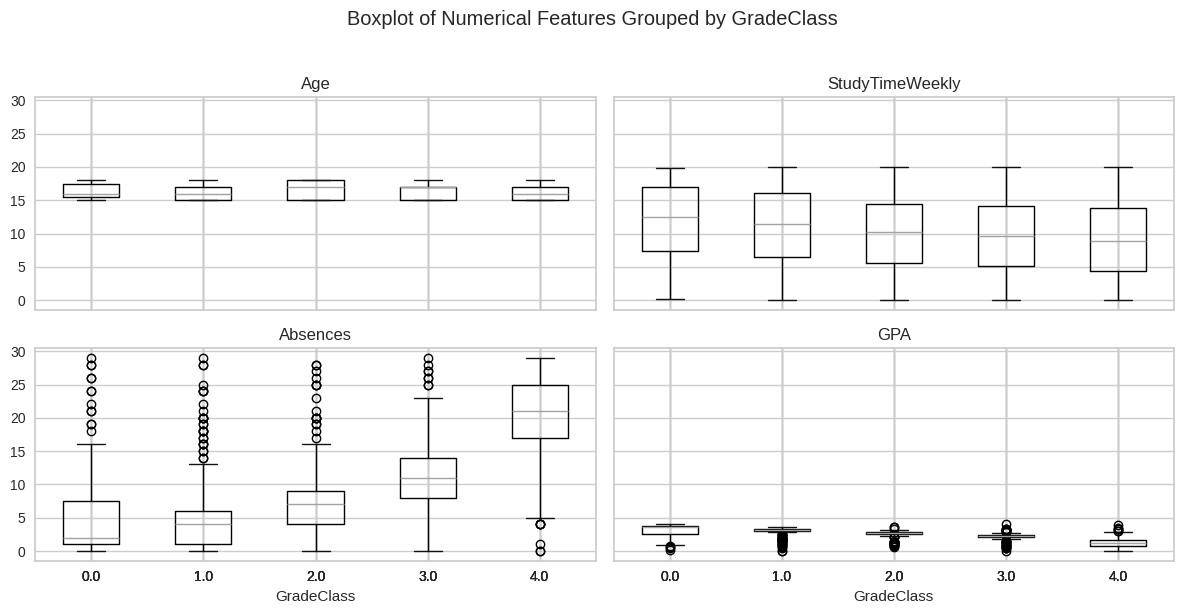

In [106]:
df.boxplot(
    column=['Age', 'StudyTimeWeekly', 'Absences', 'GPA'],
    by='GradeClass',
    figsize=(12, 6),
)
plt.suptitle('Boxplot of Numerical Features Grouped by GradeClass', y=1.02)
plt.tight_layout()
plt.show()

The boxplots present the five-number summary and outlier detection for Age, StudyTimeWeekly, Absences, and GPA grouped by GradeClass. Distinct outliers are detected as data points extending beyond the whiskers in Absences (exceptionally high absence counts) and GPA (students with unusually low values), whereas Age and StudyTimeWeekly displays a consistent spread without extreme outliers. Because these data points operate on drastically different scales and the identified outliers can skew distance-based algorithms, outlier handling and feature scaling are required during preprocessing.

### Outliers

In [107]:
from scipy.stats import zscore

numeric_cols = ['GPA', 'StudyTimeWeekly', 'Absences', 'Age']
threshold = 2

print('--- Outliers using Z-Score Method (Threshold = 2) ---')

for col in numeric_cols:
  z = abs(zscore(df[col]))
  outliers_count = (z > threshold).sum()

  print(f"Column '{col}': {outliers_count} outliers")

--- Outliers using Z-Score Method (Threshold = 2) ---
Column 'GPA': 46 outliers
Column 'StudyTimeWeekly': 0 outliers
Column 'Absences': 0 outliers
Column 'Age': 0 outliers


For outlier detection, the Z-score method was applied to the numerical features (Age, StudyTimeWeekly, Absences, and GPA) with a threshold of 2 ( ∣Z∣>2 ),this result differs from the visualizations observed in the Boxplots, as the boxplots rely on the Interquartile Range (IQR) method ( 1.5×IQR ) grouped by target classes (GradeClass). While the IQR visualizations highlight class-relative deviations, the Z-score approach was chosen here to detect global, multi-feature deviations across the entire dataset according to standard preprocessing practices.

### Histogram

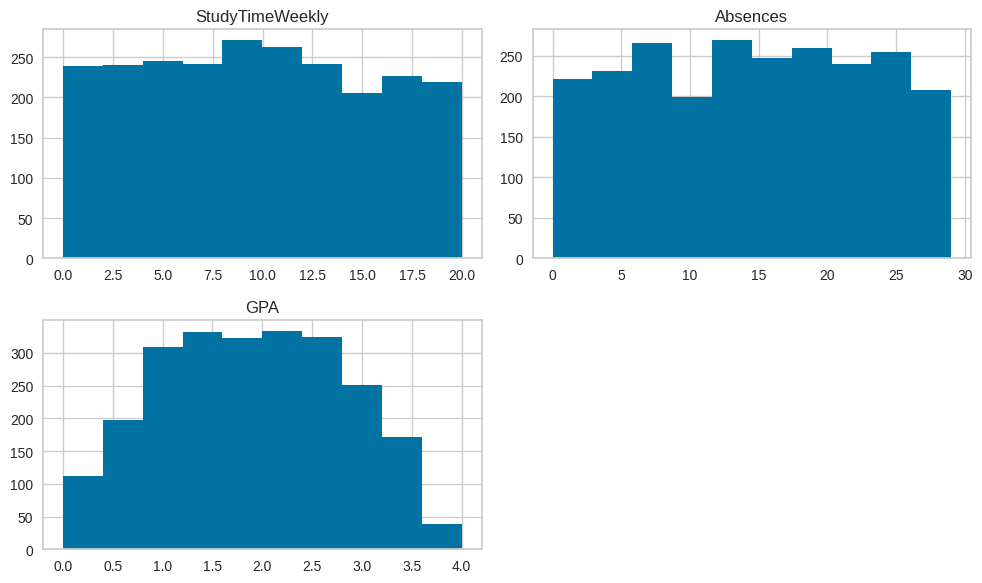

In [108]:
df[['StudyTimeWeekly', 'Absences', 'GPA']].hist(figsize=(10, 6))
plt.tight_layout()
plt.show()

The histograms represent the frequency distribution of our continuous features. GPA displays a bell-shaped distribution centered between 1.5 and 2.5, representing typical academic achievement spreads. StudyTimeWeekly and Absences are spread evenly across students. The continuous nature and differing scale widths seen in these histograms justify applying normalization or discretization during preprocessing.

### Scatter Plot

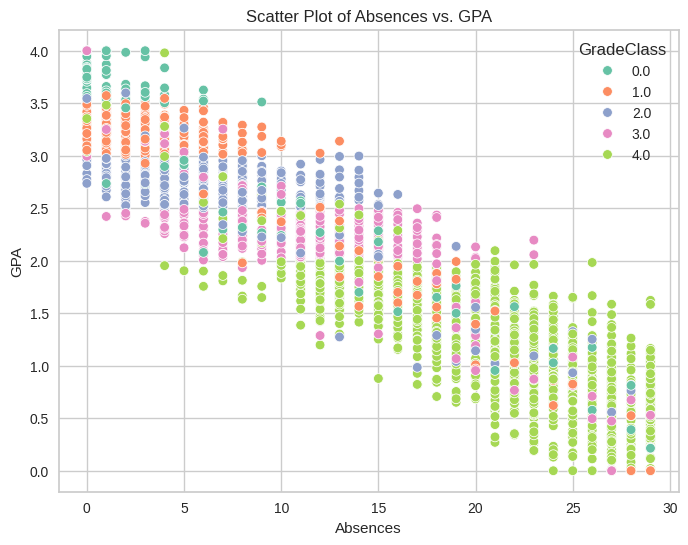

In [109]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x='Absences',
    y='GPA',
    data=df,
    hue='GradeClass',
    palette='Set2',
)
plt.title('Scatter Plot of Absences vs. GPA')
plt.xlabel('Absences')
plt.ylabel('GPA')
plt.show()

The scatter plot displays the pairwise relationship between Absences and GPA, with points colored by GradeClass. A strong negative linear pattern is evident: higher student absences correlate with lower GPA values and lower grade classes. This demonstrates that Absences carries substantial predictive power, confirming it should be retained for decision tree classification without dimensionality removal.

### Bar Plot

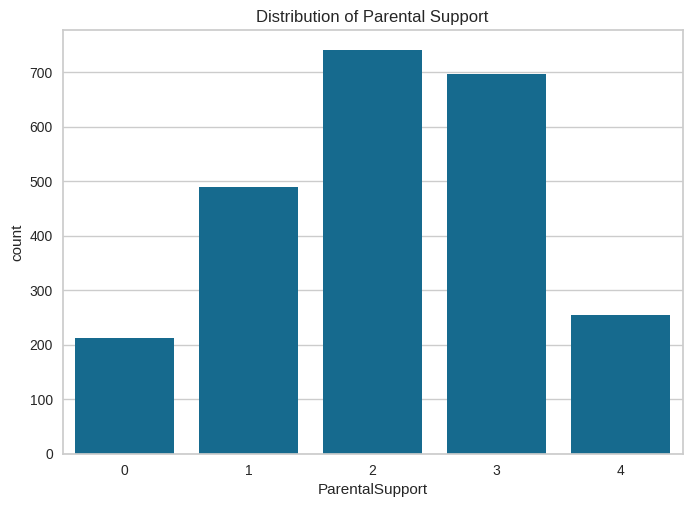

In [110]:
sns.countplot(x='ParentalSupport', data=df)
plt.title('Distribution of Parental Support')
plt.show()

The bar chart shows the student counts across all categories of ParentalSupport. The categories are balanced with sufficient representation across every level (none to very high), confirming no servere category imbalance issues exist for this predictor that would require resampling during the preprocessing phase.

### Class Label Distribution

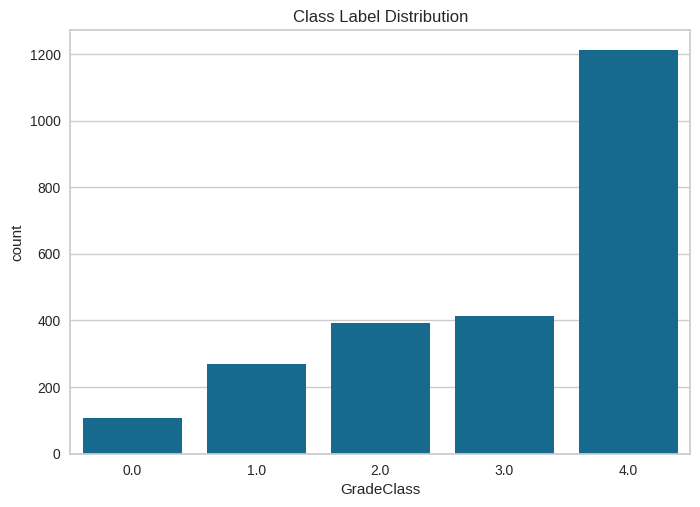

In [111]:
sns.countplot(x='GradeClass', data=df)
plt.title("Class Label Distribution")
plt.show()

The class label distribution for ⁠GradeClass⁠ shows a noticeable class imbalance. Class 4.0 is the most frequent with over 1,200 samples, while class 0.0 has the lowest count around 100 samples. This imbalance suggests that resampling techniques may be considered during preprocessing to prevent model bias.



Based on the exploratory data analysis, the dataset has no missing values. However, the presence of numerical outliers and class imbalance in ⁠GradeClass⁠ indicates that preprocessing steps such as outlier handling, feature scaling/normalization will be necessary to improve model performance.

# [4] Data Preprocessing




In [112]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from scipy.stats import zscore

In [113]:
df_processed = df.copy()

print("Raw Dataset Snapshot")
display(df.head())



Raw Dataset Snapshot


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0



## Technique 1: Noise Removal(handling outliers using z-score)


Why it was applied (Justification): Exploratory Data Analysis (EDA) in Phase 1 identified potential extreme values in continuous numerical features. Removing unusual observations helps reduce their influence on data analysis and improves data quality before applying machine learning techniques.


How and on which attributes: The Z-score method was applied to continuous numerical attributes (StudyTimeWeekly, Absences, and GPA). Rows containing an absolute Z-score greater than  2 (|Z| > 2) in any of these attributes were filtered out.


Dataset Improvement: Successfully identified and removed extreme observations while retaining 2,346 student records. This reduces the influence of unusual values and helps improve data quality for subsequent analysis and model training.

In [114]:
numeric_cols = ['StudyTimeWeekly', 'Absences', 'GPA']

z_scores = np.abs(zscore(df_processed[numeric_cols]))

df_processed = df_processed.loc[
    (z_scores < 2).all(axis=1)
    ].copy()
print(f"\nDataset shape after Outlier Removal: {df_processed.shape}")


Dataset shape after Outlier Removal: (2346, 15)


## Technique 2: Discretization(binning)

Why it was applied (Justification): GPA is a continuous numerical feature. Discretization was applied to convert GPA values into three clear categories, making GPA levels easier to interpret and analyze.


How and on which attributes: The GPA attribute was divided into three intervals using pd.cut: Low (0) for values up to 2.0, Medium (1) for values greater than 2.0 and up to 3.0, and High (2) for values greater than 3.0. A new column, GPA_Level, was created while preserving the original GPA attribute.


Dataset Improvement: Converted continuous GPA values into three meaningful levels. The resulting distribution included 1,253 students in Low, 797 in Medium, and 296 in High. This makes GPA categories easier to interpret and compare while preserving the original numerical values for further analysis.


In [115]:
bins = [-np.inf, 2.0, 3.0, np.inf]
labels = [0, 1, 2]
df_processed.loc[:, 'GPA_Level'] = pd.cut(
    df_processed['GPA'],
    bins=bins,
    labels=labels,
    include_lowest=True
    ).astype(int)
print("Discretization applied successfully")
print("\nGPA Level Counts:")
print(df_processed['GPA_Level'].value_counts().sort_index())
display(df_processed[['GPA', 'GPA_Level']].head())

Discretization applied successfully

GPA Level Counts:
GPA_Level
0    1253
1     797
2     296
Name: count, dtype: int64


,GPA,GPA_Level
0,2.929196,1
1,3.042915,2
2,0.112602,0
3,2.054218,1
4,1.288061,0


## Technique 3: Normalization(Min-Max Normalization)


Why it was applied (Justification):
StudyTimeWeekly is a continuous numerical attribute. Min-Max Normalization was applied to transform its values into a standard range between 0 and 1, making the values easier to interpret and compare.

How and on which attributes:
MinMaxScaler was applied only to the StudyTimeWeekly attribute. Its values were transformed into the range [0, 1], while other attributes, including GPA and Absences, were left unchanged.

Dataset Improvement:
The transformation successfully rescaled StudyTimeWeekly values into the range [0, 1]. This provides a standardized representation of weekly study hours while preserving the relative order of the original values.

In [116]:
scaler = MinMaxScaler()

df_processed.loc[:, 'StudyTimeWeekly'] = scaler.fit_transform(
    df_processed[['StudyTimeWeekly']]
).ravel()

print("\n--- StudyTimeWeekly successfully normalized ---")

display(df_processed[['StudyTimeWeekly']].head())


--- StudyTimeWeekly successfully normalized ---


,StudyTimeWeekly
0,0.992773
1,0.771270
2,0.210718
3,0.501965
4,0.233840


RAW DATASET VS PROCESSED DATASET

In [117]:
print("\nRaw Dataset (Before Preprocessing)")
display(df.head())

print("\nPreprocessed Dataset (After Preprocessing)")
display(df_processed.head())



Raw Dataset (Before Preprocessing)


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0



Preprocessed Dataset (After Preprocessing)


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass,GPA_Level
0,1001,17,1,0,2,0.992773,7,1,2,0,0,1,0,2.929196,2.0,1
1,1002,18,0,0,1,0.771270,0,0,1,0,0,0,0,3.042915,1.0,2
2,1003,15,0,2,3,0.210718,26,0,2,0,0,0,0,0.112602,4.0,0
3,1004,17,1,0,3,0.501965,14,0,3,1,0,0,0,2.054218,3.0,1
4,1005,17,1,0,2,0.233840,17,1,3,0,0,0,0,1.288061,4.0,0


Save the preprocessed Data

In [118]:
df_processed.to_csv('Preprocessed_dataset.csv', index=False)
print("\nSuccess: 'Preprocessed_dataset.csv' has been saved successfully!")




Success: 'Preprocessed_dataset.csv' has been saved successfully!


# [5] Data Mining Technique
##Classification – Decision Tree (Gini index)

We use a Decision Tree to predict each student's GradeClass (0–4). A decision tree is easy to interpret, because its rules show which student characteristics lead to each grade class [5]. This helps teachers and advisors understand why a student is predicted to be at risk.

- **Package:** scikit-learn [2]
- **Methods:**
  - train_test_split(X, y, test_size=..., random_state=1, stratify=y) (sklearn.model_selection) splits the data into three partitions: 90/10, 80/20 and 70/30 (training/testing). stratify=y keeps the same class proportions in the training and testing sets because the classes are imbalanced.
  - DecisionTreeClassifier(random_state=1) (sklearn.tree) builds the tree using the Gini index as the attribute selection measure. .fit() trains the model and .predict() predicts the testing set.
  - metrics.accuracy_score(), confusion_matrix() and ConfusionMatrixDisplay (sklearn.metrics) evaluate the models.
  - tree.plot_tree() (sklearn.tree) visualizes the decision tree.
- StudentID, GPA and GPA_Level are removed from the predictors, because StudentID is only an identifier and GradeClass is derived from GPA.

##Clustering – K-means

We use K-means to group students with similar characteristics without using the class label. K-means is simple and efficient, and each cluster center describes the average student in that group, which helps us identify student profiles.

- **Packages:** scikit-learn [2] and yellowbrick [8]
- **Methods:**
  - StandardScaler() (sklearn.preprocessing) standardizes the selected attributes because K-means relies on Euclidean distance.
  - KMeans(n_clusters=k, random_state=42, n_init=10) (sklearn.cluster) applies K-means for K = 3, 4 and 5. .inertia_ gives the total within-cluster sum of squares (WSS), used in the Elbow method.
  - silhouette_score() [6] and calinski_harabasz_score() [7] (sklearn.metrics) evaluate the clusters.
  - SilhouetteVisualizer (yellowbrick.cluster) plots the silhouette of each cluster.
  - PCA(n_components=2) (sklearn.decomposition) reduces the data to two dimensions to visualize the clusters.

# [6] Evaluation and Comparison

##For Classification

### Classification: Decision Tree (Gini Index)
We apply Decision Tree classification using the Gini index as the attribute selection measure (the default in DecisionTreeClassifier()), with three partition sizes: 90/10, 80/20 and 70/30 (training/testing).


In [119]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn import tree
import matplotlib.pyplot as plt

In [120]:
df_cls = pd.read_csv("Preprocessed_dataset.csv")
print(df_cls.head())

   StudentID  Age  Gender  Ethnicity  ParentalEducation  StudyTimeWeekly  \
0       1001   17       1          0                  2         0.992773   
1       1002   18       0          0                  1         0.771270   
2       1003   15       0          2                  3         0.210718   
3       1004   17       1          0                  3         0.501965   
4       1005   17       1          0                  2         0.233840   

   Absences  Tutoring  ParentalSupport  Extracurricular  Sports  Music  \
0         7         1                2                0       0      1   
1         0         0                1                0       0      0   
2        26         0                2                0       0      0   
3        14         0                3                1       0      0   
4        17         1                3                0       0      0   

   Volunteering       GPA  GradeClass  GPA_Level  
0             0  2.929196         2.0          

In [121]:
fn = df_cls.drop(columns=['StudentID', 'GPA', 'GPA_Level', 'GradeClass']).keys().tolist()
X = df_cls[fn]
y = df_cls['GradeClass'].astype(int)
cn = ['0', '1', '2', '3', '4']

print("Features:", fn)
print("Classes:", cn)

Features: ['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering']
Classes: ['0', '1', '2', '3', '4']


Training set: 2111 records
Testing set: 235 records
Accuracy: 0.6170212765957447
[[ 1  5  1  1  1]
 [ 6 14  5  0  2]
 [ 0  9 16  9  5]
 [ 1  2  8 20 10]
 [ 3  5  5 12 94]]


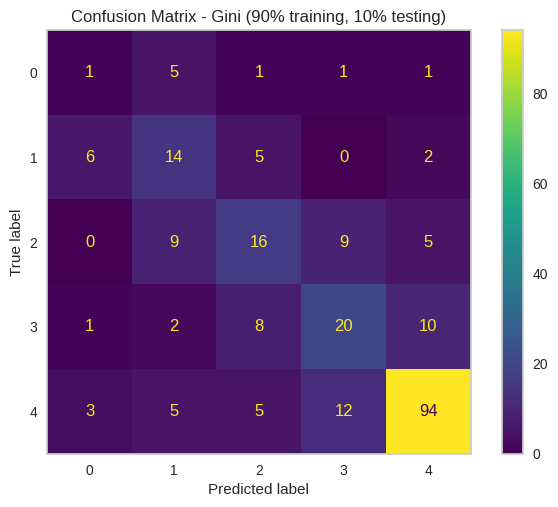

In [122]:
# Partition 1: 90% Training, 10% Testing
# stratify=y keeps the same class proportions in training and testing sets because our classes are imbalanced
X_train_90, X_test_90, y_train_90, y_test_90 = train_test_split(X, y, test_size=0.1, random_state=1, stratify=y)
print("Training set:", X_train_90.shape[0], "records")
print("Testing set:", X_test_90.shape[0], "records")

clf_90 = DecisionTreeClassifier(random_state=1)
clf_90 = clf_90.fit(X_train_90, y_train_90)
y_pred_90 = clf_90.predict(X_test_90)

acc_90 = metrics.accuracy_score(y_test_90, y_pred_90)
print("Accuracy:", acc_90)

cm_90 = confusion_matrix(y_test_90, y_pred_90)
print(cm_90)

disp = ConfusionMatrixDisplay.from_estimator(clf_90, X_test_90, y_test_90, display_labels=cn)
disp.ax_.grid(False)
plt.title("Confusion Matrix - Gini (90% training, 10% testing)")
plt.show()

Training set: 1876 records
Testing set: 470 records
Accuracy: 0.6042553191489362
[[  2   9   2   2   2]
 [ 12  20  16   3   2]
 [  1  16  34  17  10]
 [  1   5  18  36  23]
 [  7   9  10  21 192]]


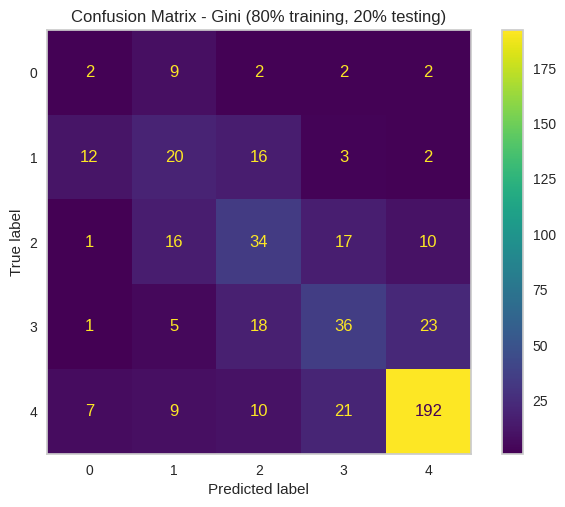

In [123]:
# Partition 2: 80% Training, 20% Testing
X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y)
print("Training set:", X_train_80.shape[0], "records")
print("Testing set:", X_test_80.shape[0], "records")

clf_80 = DecisionTreeClassifier(criterion="gini", random_state=1)
clf_80 = clf_80.fit(X_train_80, y_train_80)
y_pred_80 = clf_80.predict(X_test_80)

acc_80 = metrics.accuracy_score(y_test_80, y_pred_80)
print("Accuracy:", acc_80)

cm_80 = confusion_matrix(y_test_80, y_pred_80)
print(cm_80)

disp = ConfusionMatrixDisplay.from_estimator(clf_80, X_test_80, y_test_80, display_labels=cn)
disp.ax_.grid(False)
plt.title("Confusion Matrix - Gini (80% training, 20% testing)")
plt.show()

Training set: 1642 records
Testing set: 704 records
Accuracy: 0.6136363636363636
[[  3  13   1   6   2]
 [  8  34  23   7   8]
 [  3  18  54  30  12]
 [  0  11  21  54  38]
 [  5  13  17  36 287]]


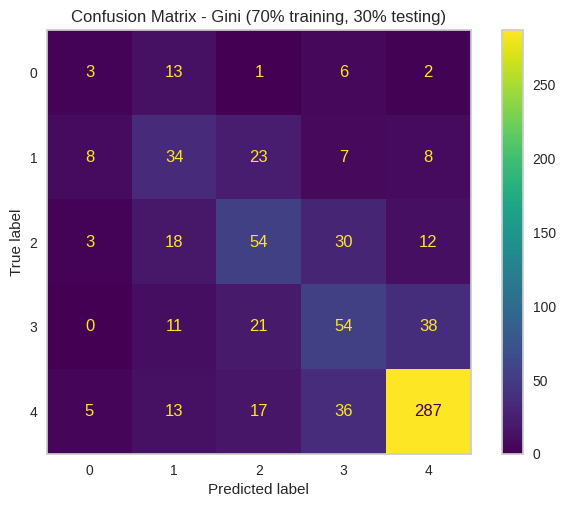

In [124]:
# Partition 3: 70% Training, 30% Testing

X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)
print("Training set:", X_train_70.shape[0], "records")
print("Testing set:", X_test_70.shape[0], "records")

clf_70 = DecisionTreeClassifier(criterion="gini", random_state=1)
clf_70 = clf_70.fit(X_train_70, y_train_70)
y_pred_70 = clf_70.predict(X_test_70)

acc_70 = metrics.accuracy_score(y_test_70, y_pred_70)
print("Accuracy:", acc_70)

cm_70 = confusion_matrix(y_test_70, y_pred_70)
print(cm_70)

disp = ConfusionMatrixDisplay.from_estimator(clf_70, X_test_70, y_test_70, display_labels=cn)
disp.ax_.grid(False)
plt.title("Confusion Matrix - Gini (70% training, 30% testing)")
plt.show()

### Accuracy Table (Gini Index)

| | 90% training set 10% testing set | 80% training set 20% testing set | 70% training set 30% testing set |
|---|---|---|---|
| **Accuracy** | 61.70% | 60.43% | 61.36% |

The Decision Tree with the Gini index performs best on the 90/10 partition (61.70%), followed by 70/30 (61.36%) and 80/20 (60.43%). The differences are small (about 1.3 percentage points), so the model performs consistently across partitions. The confusion matrices show that the model predicts class 4 (the largest class) best and class 0 (the smallest class) worst, and most errors are between neighbouring classes (1–2, 2–3, 3–4). The tree for the 90/10 partition is very deep (depth 25, 612 leaves), which indicates overfitting and partly explains the moderate accuracy.

Tree depth: 25
Number of leaves: 612


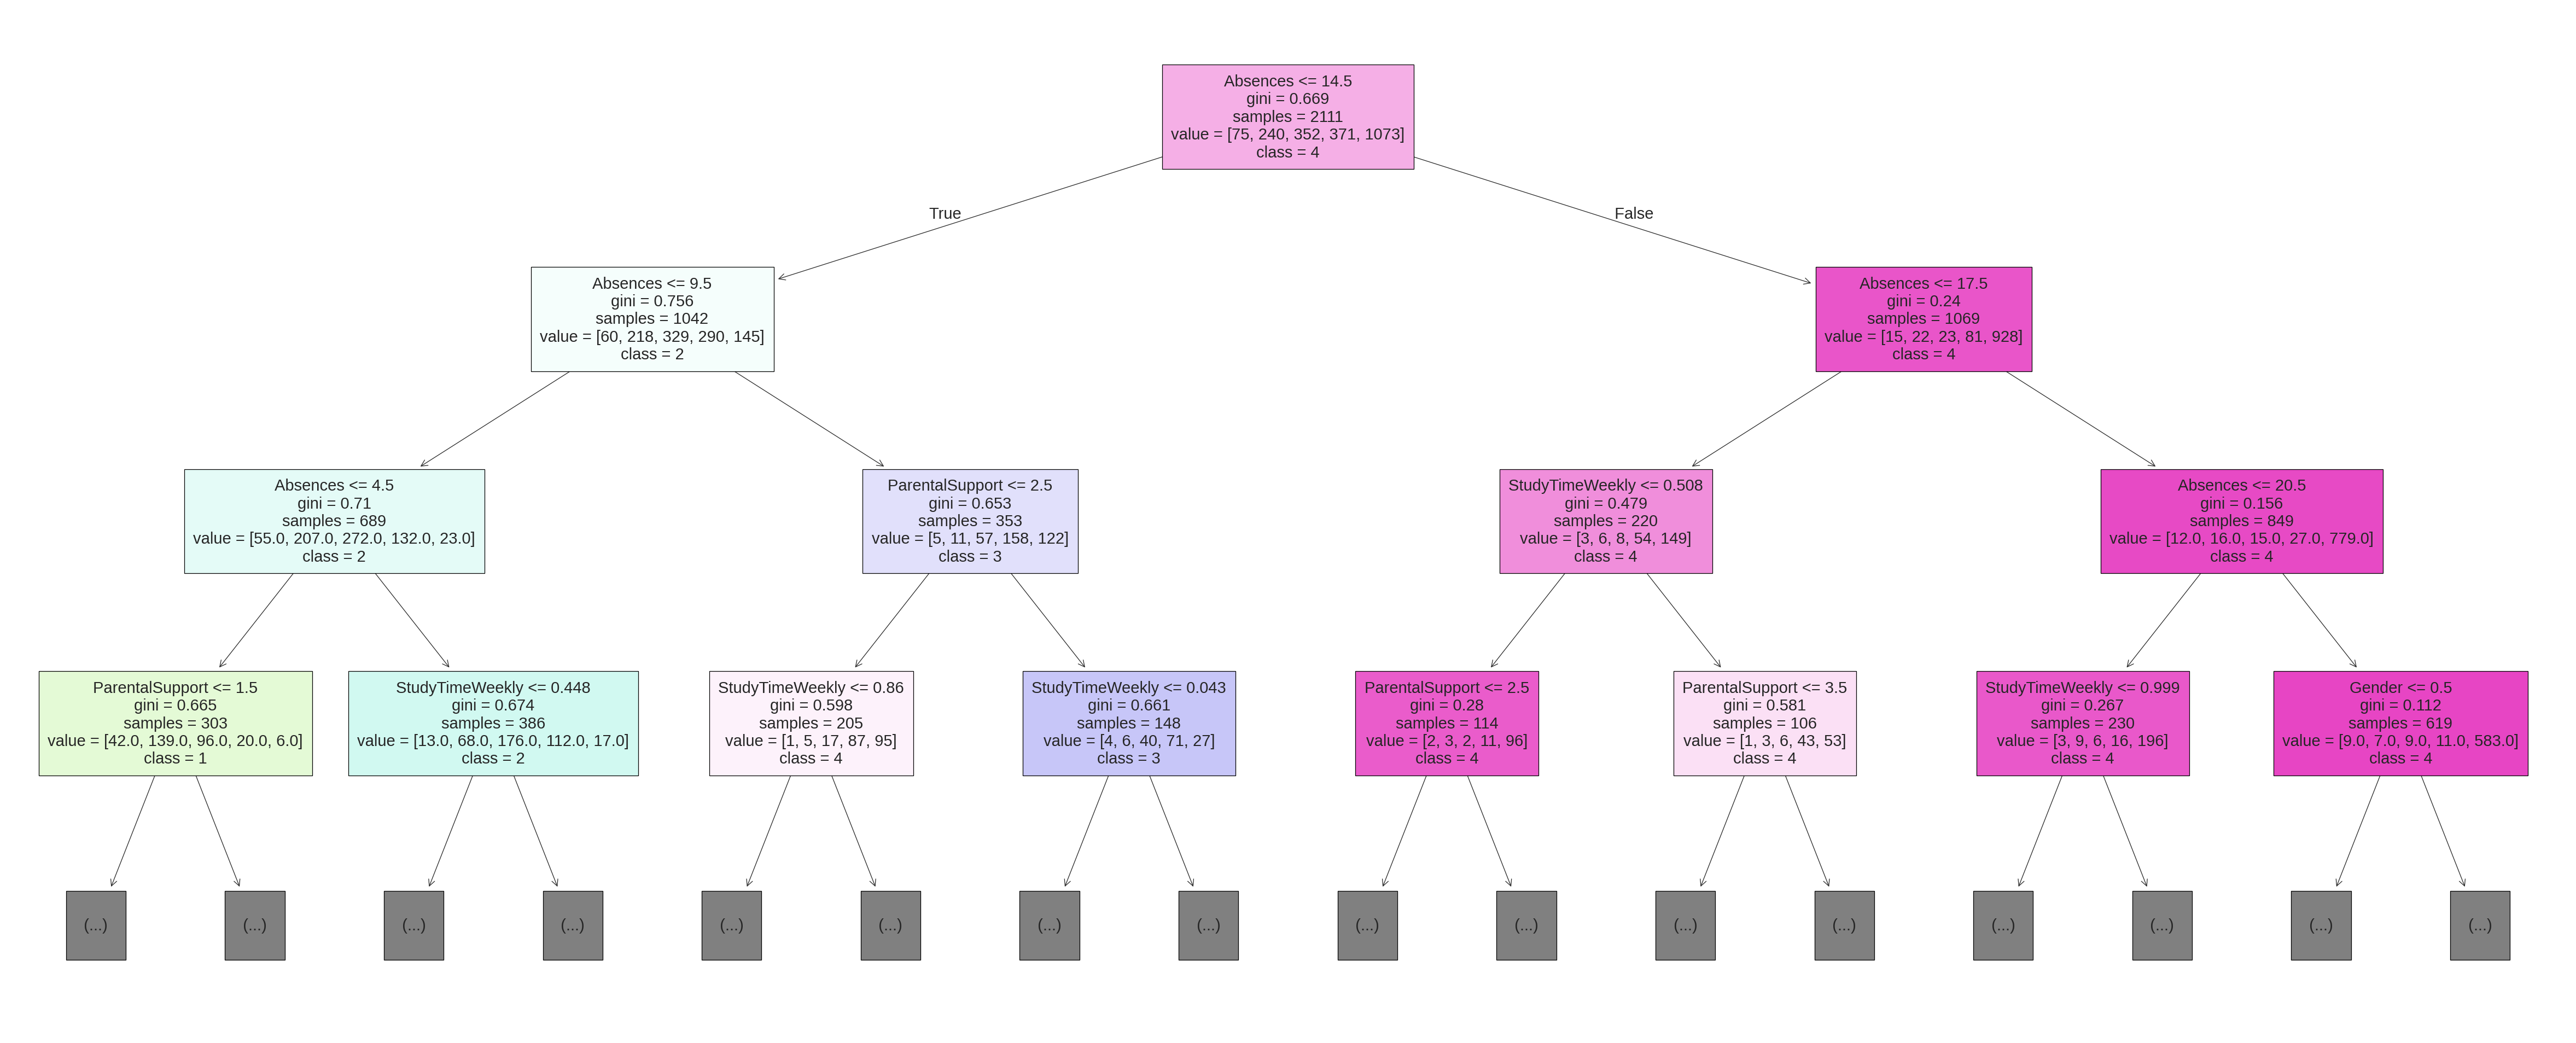

In [125]:
# to check the tree size
print("Tree depth:", clf_90.get_depth())
print("Number of leaves:", clf_90.get_n_leaves())

fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(20, 8), dpi=300)

tree.plot_tree(clf_90,
               feature_names=fn,
               class_names=cn,
               filled=True,
               max_depth=3, # display only the top 3 levels because the full tree is too deep to read
               fontsize=7
               );

fig.savefig('GradeClass_DT_gini.png')

###For Clustering

In [126]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import calinski_harabasz_score
from yellowbrick.cluster import SilhouetteVisualizer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [128]:
df = pd.read_csv("Preprocessed_dataset.csv")
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass,GPA_Level
0,1001,17,1,0,2,0.992773,7,1,2,0,0,1,0,2.929196,2.0,1
1,1002,18,0,0,1,0.771270,0,0,1,0,0,0,0,3.042915,1.0,2
2,1003,15,0,2,3,0.210718,26,0,2,0,0,0,0,0.112602,4.0,0
3,1004,17,1,0,3,0.501965,14,0,3,1,0,0,0,2.054218,3.0,1
4,1005,17,1,0,2,0.233840,17,1,3,0,0,0,0,1.288061,4.0,0


In [129]:
features = df.drop(
    columns=["StudentID","GradeClass","GPA_Level","Age","Gender","Ethnicity","ParentalEducation"]
)

scaler = StandardScaler()
scaled_features= scaler.fit_transform(features)

df_scaled=pd.DataFrame(
  scaled_features,
  columns=features.columns
)

df_scaled.head()

,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA
0,1.780696,-0.907690,1.530320,-0.107816,-0.789639,-0.657445,2.024846,-0.433414,1.163838
1,0.995946,-1.746903,-0.653458,-1.004755,-0.789639,-0.657445,-0.493865,-0.433414,1.292686
2,-0.990007,1.370172,-0.653458,-0.107816,-0.789639,-0.657445,-0.493865,-0.433414,-2.027458
3,0.041838,-0.068478,-0.653458,0.789122,1.266402,-0.657445,-0.493865,-0.433414,0.172459
4,-0.908087,0.291185,1.530320,0.789122,-0.789639,-0.657445,-0.493865,-0.433414,-0.695623


Feature Selection and Scaling for K-Means Clustering

Since clustering is an unsupervised learning technique, we removed GradeClass and GPA_Level to avoid using target labels and redundant information. We excluded Gender and Ethnicity because their nominal numerical codes do not represent meaningful distances. Age and ParentalEducation were also removed to focus on academic behavior and performance.

The remaining nine attributes were StudyTimeWeekly, Absences, Tutoring, ParentalSupport, Extracurricular, Sports, Music, Volunteering, and GPA.

Since K-means relies on Euclidean distance, we applied StandardScaler so that all attributes have the same scale and no attribute dominates the distance calculation.

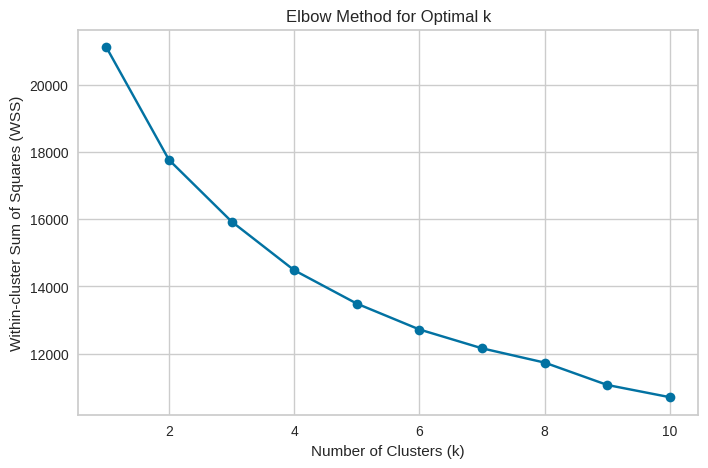

In [130]:
wss_values =[]
k_values = range(1, 11)
for k in k_values:
  kmeans=KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(df_scaled)
  wss_values.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(k_values, wss_values, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-cluster Sum of Squares (WSS)')
plt.title('Elbow Method for Optimal k')
plt.show()

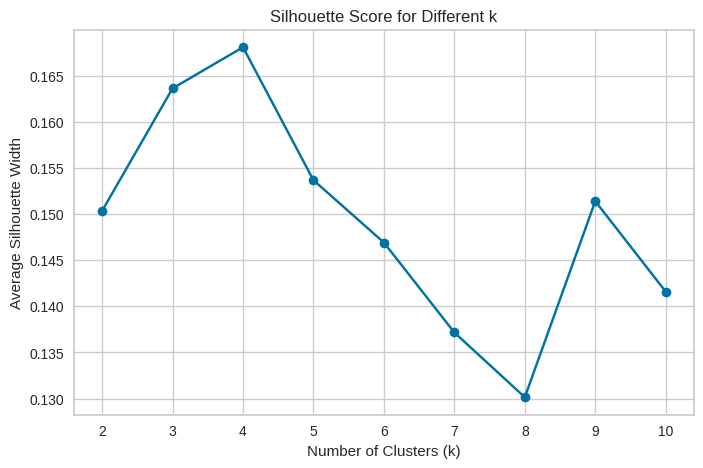

In [131]:
silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
   kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
   labels = kmeans.fit_predict(df_scaled)
   score = silhouette_score(df_scaled, labels)
   silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Average Silhouette Width')
plt.title('Silhouette Score for Different k')
plt.show()

The elbow curve decreases sharply until K=4 and then begins to flatten. In the silhouette plot, the highest values are at K=3 and K=4, and the score drops after K=4. Therefore, we selected K = 3, 4 and 5 for comparison.

In [132]:
np.random.seed(42)
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_3.fit(df_scaled)

print("Cluster Centers:")
print(kmeans_3.cluster_centers_)

print("\nCluster Labels:")
labels_3 = kmeans_3.labels_
print(labels_3)

silhouette_3 = silhouette_score(df_scaled, labels_3)
wss_3 = kmeans_3.inertia_
print("\nAverage Silhouette Width:", silhouette_3)
print("Total WSS:", wss_3)

Cluster Centers:
[[-0.05963211 -0.02582255 -0.11781422 -0.02561692 -0.02485818 -0.00566168
   0.02888643  2.30726031 -0.01841569]
 [ 0.08222563 -0.83765462  0.05970291  0.07047995  0.05071047 -0.0145053
   0.02213877 -0.43341447  0.84808249]
 [-0.05960663  0.84480043 -0.01532658 -0.06065657 -0.04123169  0.01658514
  -0.03290767 -0.43341447 -0.83860173]]

Cluster Labels:
[1 1 2 ... 0 2 0]

Average Silhouette Width: 0.16360644648785716
Total WSS: 15929.27715554348


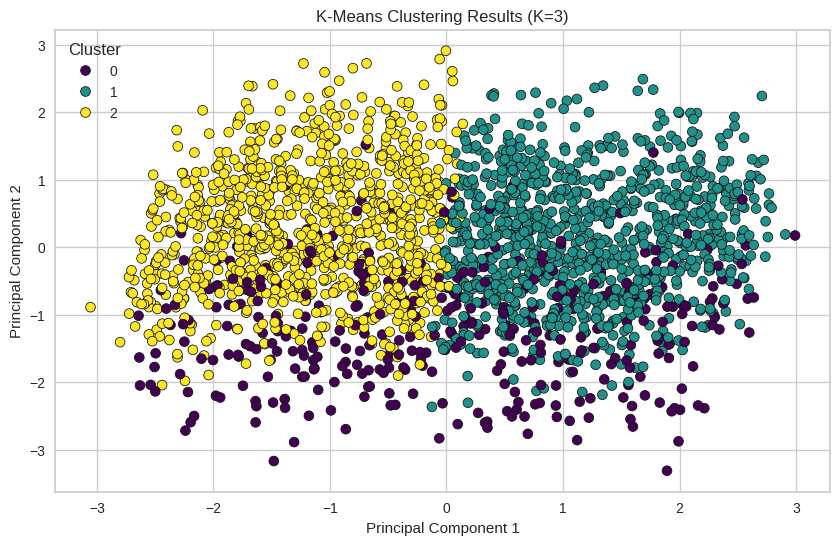

In [133]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pca_features = pca.fit_transform(df_scaled)
pca_df = pd.DataFrame(pca_features, columns=['PC1', 'PC2'])
pca_df['Cluster'] = labels_3

plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', hue='Cluster', data=pca_df, palette='viridis', edgecolor='k')
plt.title('K-Means Clustering Results (K=3)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

The average silhouette score is: 0.16360644648785716


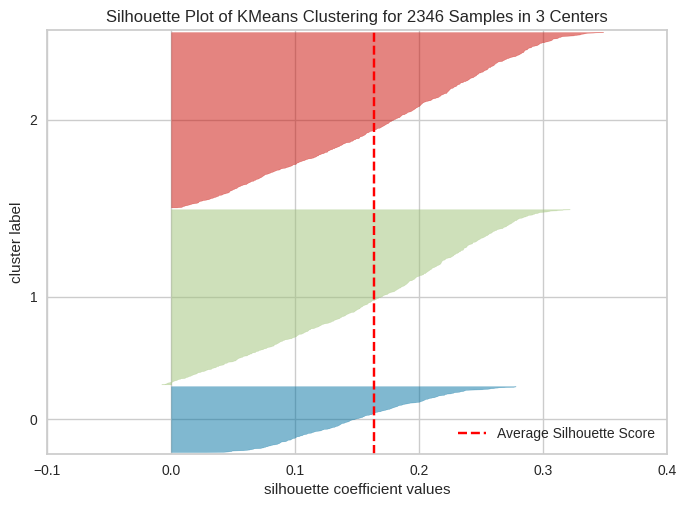

In [134]:
visualizer = SilhouetteVisualizer(KMeans(n_clusters=3, random_state=42, n_init=10), colors='yellowbrick')
visualizer.fit(df_scaled)
print("The average silhouette score is:", visualizer.silhouette_score_)
visualizer.show();

K = 3 (Silhouette Score = 0.164, WSS = 15929): The students are divided into three clusters. Cluster 0 is characterized by students who participate in volunteering, with average absences and GPA. Cluster 1 includes students with low absences and high GPA, while Cluster 2 includes students with high absences and low GPA.

In [135]:
np.random.seed(42)
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_4.fit(df_scaled)

print("Cluster Centers:")
print(kmeans_4.cluster_centers_)

print("\nCluster Labels:")
labels_4 = kmeans_4.labels_
print(labels_4)

silhouette_4 = silhouette_score(df_scaled, labels_4)
wss_4 = kmeans_4.inertia_
print("\nAverage Silhouette Width:", silhouette_4)
print("Total WSS:", wss_4)

Cluster Centers:
[[ 1.09244296e-01 -8.56768715e-01  6.79688029e-02  3.97668525e-02
   6.26739679e-02  2.05522748e-02 -4.93864798e-01 -4.33414468e-01
   8.32728260e-01]
 [ 1.21378609e-02  1.35338715e-02 -2.62631447e-02  7.71920584e-02
  -2.19787139e-02 -6.02107900e-02  2.02484567e+00 -4.33414468e-01
   1.28778303e-01]
 [-8.43722960e-02  8.36761590e-01  5.94454855e-04 -6.34132350e-02
  -3.89803940e-02  1.11983062e-02 -4.93864798e-01 -4.33414468e-01
  -8.60580228e-01]
 [-5.96321129e-02 -2.58225467e-02 -1.17814223e-01 -2.56169188e-02
  -2.48581808e-02 -5.66167732e-03  2.88864316e-02  2.30726031e+00
  -1.84156925e-02]]

Cluster Labels:
[1 0 2 ... 3 1 3]

Average Silhouette Width: 0.16806818839938653
Total WSS: 14479.90316592638


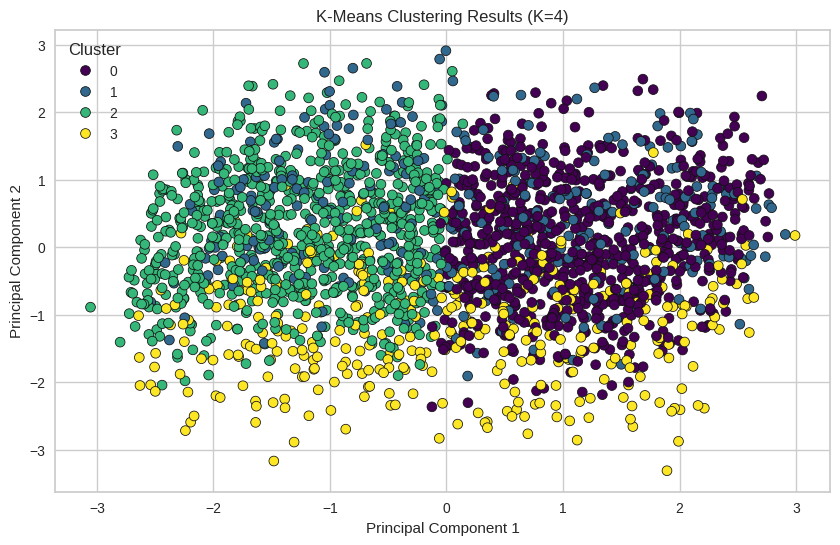

In [136]:
pca_df = pd.DataFrame(pca_features, columns=['PC1', 'PC2'])
pca_df['Cluster'] = labels_4

plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', hue='Cluster', data=pca_df, palette='viridis', edgecolor='k')
plt.title('K-Means Clustering Results (K=4)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

The average silhouette score is: 0.16806818839938653


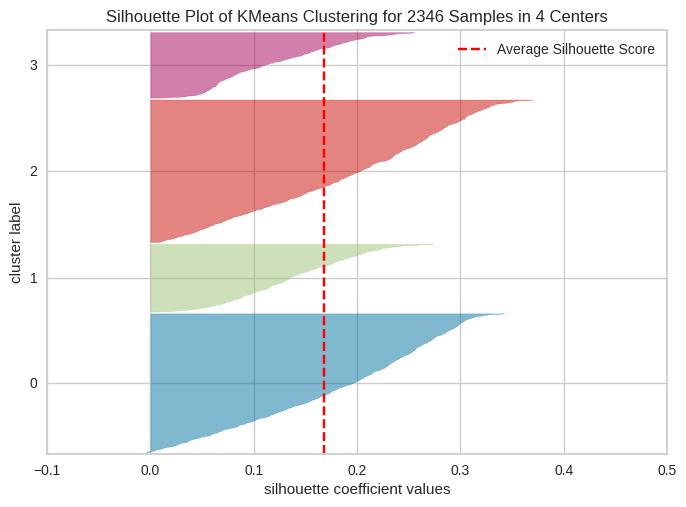

In [137]:

visualizer = SilhouetteVisualizer(KMeans(n_clusters=4, random_state=42, n_init=10), colors='yellowbrick')
visualizer.fit(df_scaled)
print("The average silhouette score is:", visualizer.silhouette_score_)
visualizer.show();

K = 4 (Silhouette Score = 0.168, WSS = 14480): The students are divided into four clusters. Cluster 0 includes students with low absences and high GPA. Cluster 1 is characterized by students who participate in music, with average absences and GPA. Cluster 2 includes students with high absences and low GPA. Cluster 3 is characterized by students who participate in volunteering, with average absences and GPA.

In [138]:
np.random.seed(42)
kmeans_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
kmeans_5.fit(df_scaled)

print("Cluster Centers:")
print(kmeans_5.cluster_centers_)

print("\nCluster Labels:")
labels_5 = kmeans_5.labels_
print(labels_5)

silhouette_5 = silhouette_score(df_scaled, labels_5)
wss_5 = kmeans_5.inertia_
print("\nAverage Silhouette Width:", silhouette_5)
print("Total WSS:", wss_5)

Cluster Centers:
[[ 0.02698773  0.45301697  1.53032034 -0.08673925 -0.02197871 -0.00901925
  -0.4938648  -0.43341447 -0.28713162]
 [-0.12323005  0.77421241 -0.65345796 -0.04965288 -0.05283242  0.04517156
  -0.4938648  -0.43341447 -0.88134132]
 [ 0.12736954 -0.99967461 -0.23983703  0.06782831  0.09152148  0.00344311
  -0.4938648  -0.43341447  0.93731549]
 [-0.05963211 -0.02582255 -0.11781422 -0.02561692 -0.02485818 -0.00566168
   0.02888643  2.30726031 -0.01841569]
 [ 0.01213786  0.01353387 -0.02626314  0.07719206 -0.02197871 -0.06021079
   2.02484567 -0.43341447  0.1287783 ]]

Cluster Labels:
[4 2 1 ... 3 4 3]

Average Silhouette Width: 0.1536597586668954
Total WSS: 13486.848741079042


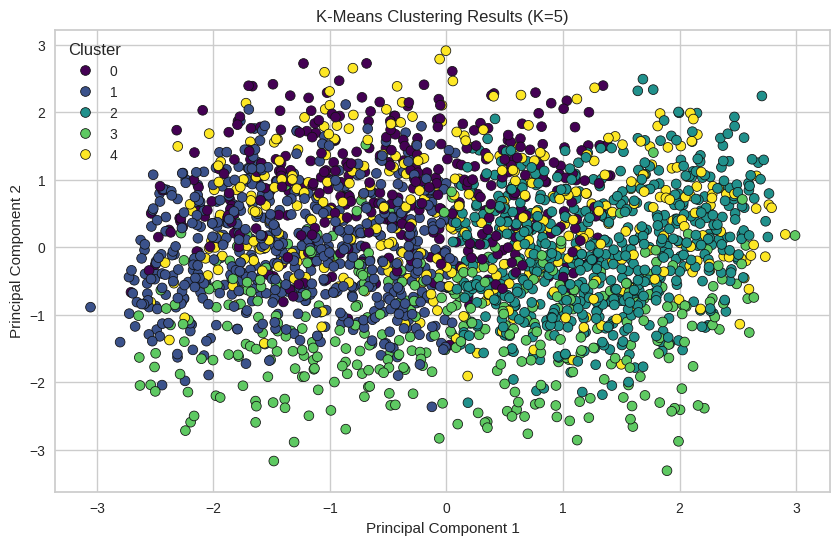

In [139]:
pca_df = pd.DataFrame(pca_features, columns=['PC1', 'PC2'])
pca_df['Cluster'] = labels_5

plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', hue='Cluster', data=pca_df, palette='viridis', edgecolor='k')
plt.title('K-Means Clustering Results (K=5)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

The average silhouette score is: 0.1536597586668954


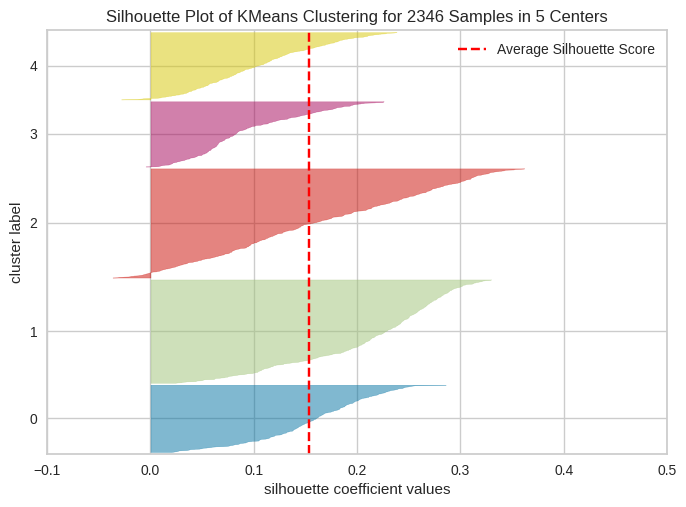

In [140]:
visualizer = SilhouetteVisualizer(KMeans(n_clusters=5, random_state=42, n_init=10), colors='yellowbrick')
visualizer.fit(df_scaled)
print("The average silhouette score is:", visualizer.silhouette_score_)
visualizer.show();

K = 5 (Silhouette Score = 0.154, WSS = 13487): The students are divided into five clusters. Cluster 0 includes students who receive tutoring, with slightly above-average absences and slightly below-average GPA. Cluster 1 includes students with high absences and low GPA, while Cluster 2 includes students with low absences and high GPA. Cluster 3 is characterized by students who participate in volunteering, with average absences and GPA. Cluster 4 is characterized by students who participate in music, with average absences and GPA.

In [141]:
table = pd.DataFrame({
    'K=3': [silhouette_3, wss_3],
    'K=4': [silhouette_4, wss_4],
    'K=5': [silhouette_5, wss_5]
}, index=['Average Silhouette width', 'total within-cluster sum of square'])
table

,K=3,K=4,K=5
Average Silhouette width,0.163606,0.168068,0.153660
total within-cluster sum of square,15929.277156,14479.903166,13486.848741


In [142]:

print("Calinski-Harabasz K=3:", calinski_harabasz_score(df_scaled, labels_3))
print("Calinski-Harabasz K=4:", calinski_harabasz_score(df_scaled, labels_4))
print("Calinski-Harabasz K=5:", calinski_harabasz_score(df_scaled, labels_5))

Calinski-Harabasz K=3: 381.305400851882
Calinski-Harabasz K=4: 357.6711597713471
Calinski-Harabasz K=5: 330.9779629086112


Calinski-Harabasz Index

We used the Calinski-Harabasz index as an additional evaluation metric. It measures the ratio of between-cluster dispersion to within-cluster dispersion, where a higher value indicates better-defined clusters. K=3 achieved the highest score (381.31), followed by K=4 (357.67) and K=5 (330.98).

Although the Calinski-Harabasz index favors K=3, both the Silhouette Score and the Elbow Method favor K=4. According to the majority rule, K=4 was selected as the optimal number of clusters, as it was supported by two out of the three evaluation methods.

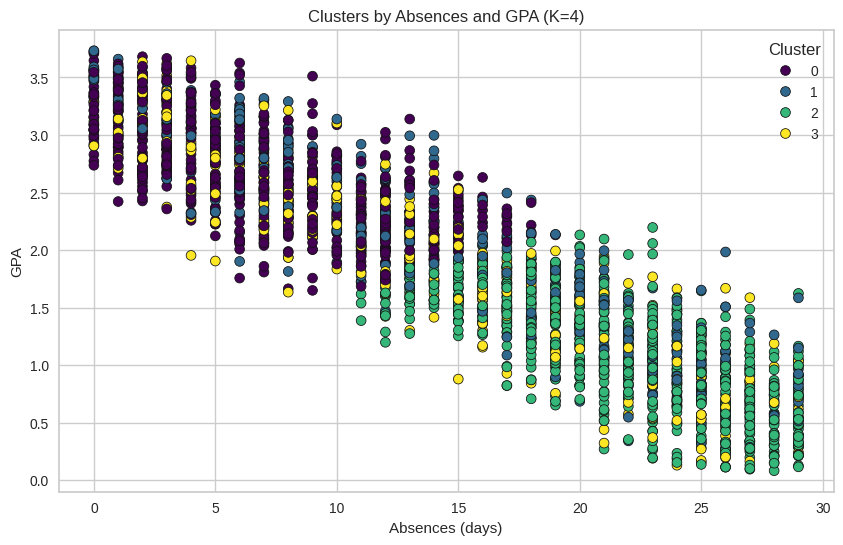

In [143]:
plot_df = features.copy()
plot_df['Cluster'] = labels_4

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Absences', y='GPA', hue='Cluster', data=plot_df, palette='viridis', edgecolor='k')
plt.title('Clusters by Absences and GPA (K=4)')
plt.xlabel('Absences (days)')
plt.ylabel('GPA')
plt.legend(title='Cluster')
plt.show()

In [144]:
cluster_centers = pd.DataFrame( kmeans_4.cluster_centers_, columns=features.columns )
cluster_centers.index.name = "Cluster"
display(cluster_centers.round(2))

,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA
Cluster,,,,,,,,,
0,0.11,-0.86,0.07,0.04,0.06,0.02,-0.49,-0.43,0.83
1,0.01,0.01,-0.03,0.08,-0.02,-0.06,2.02,-0.43,0.13
2,-0.08,0.84,0.00,-0.06,-0.04,0.01,-0.49,-0.43,-0.86
3,-0.06,-0.03,-0.12,-0.03,-0.02,-0.01,0.03,2.31,-0.02


Clusters by Absences and GPA (K=4)

This plot shows the four clusters using the original values of Absences and GPA. A negative relationship is observed, as students with more absences tend to have lower GPA.

Cluster 0 is concentrated in the upper-left area, representing students with relatively low absences and high GPA. Cluster 2 is concentrated in the lower-right area, representing students with relatively high absences and low GPA.

Clusters 1 and 3 are characterized mainly by extracurricular activities. Cluster 1 shows a high level of music participation, while Cluster 3 shows a high level of volunteering participation. Their average Absences and GPA values remain close to the overall mean.

Overall, Absences and GPA appear to be important characteristics for distinguishing students with different academic performance levels. However, since K-means considers all selected features, the separation between clusters cannot be attributed to Absences and GPA alone. Other academic and extracurricular characteristics also contribute to the clustering results.

# [7] Findings and Discussion

## Classification Findings

The best classification model is the **Decision Tree with the Gini index trained on the 90/10 partition**, with an accuracy of **61.70%** (compared with 60.43% for 80/20 and 61.36% for 70/30). The final decision tree for this partition (Figure 1) reveals the following information:

**Figure 1: Final Decision Tree (Gini index, 90/10 partition) – top levels**


Tree depth: 25
Number of leaves: 612


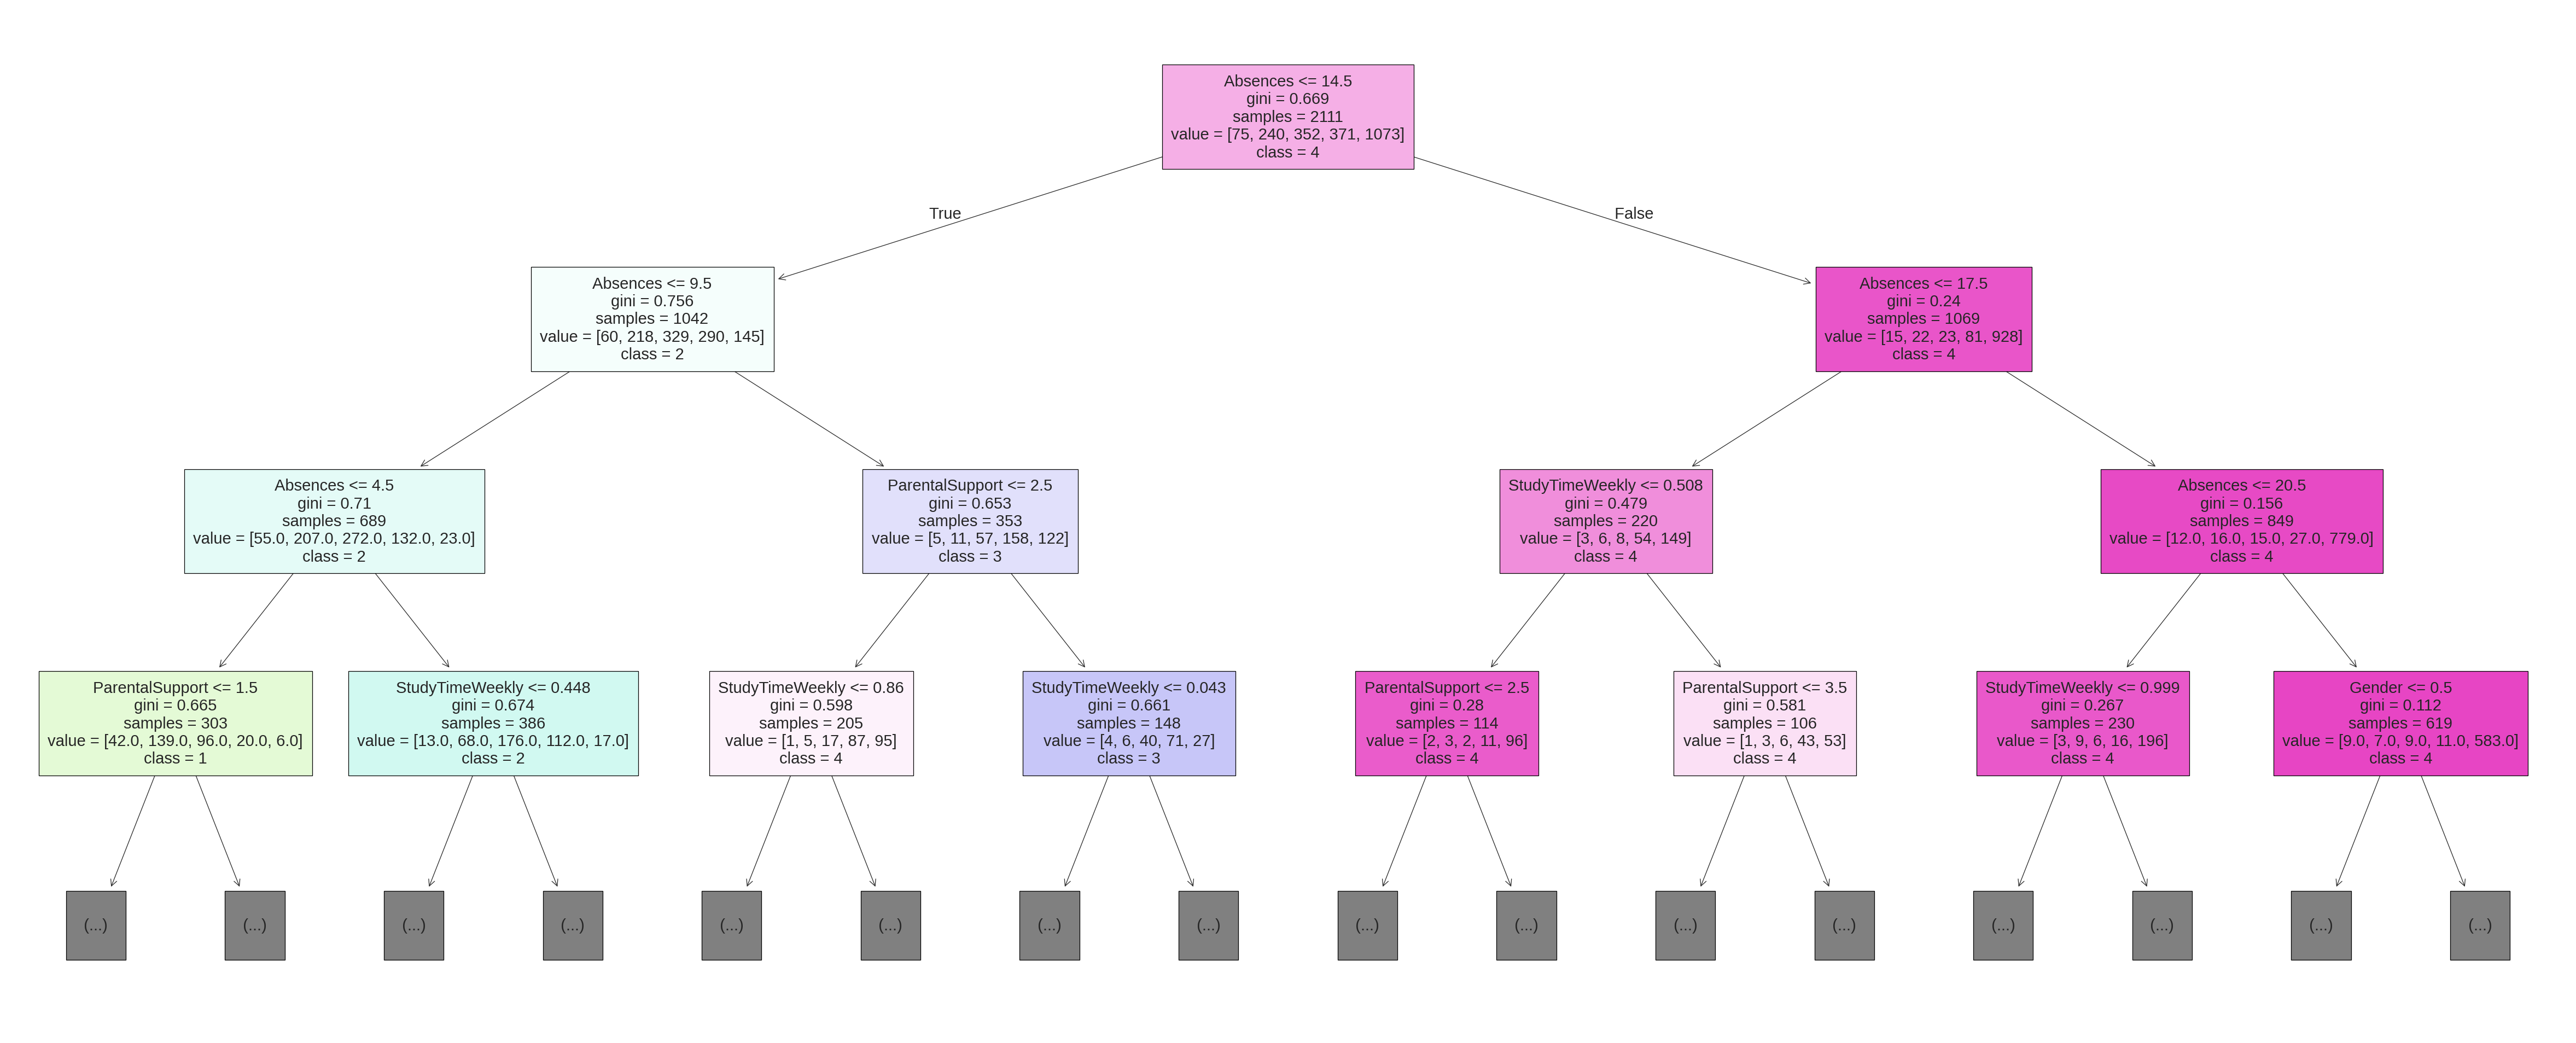

In [145]:
# to check the tree size
print("Tree depth:", clf_90.get_depth())
print("Number of leaves:", clf_90.get_n_leaves())

fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(20, 8), dpi=300)

tree.plot_tree(clf_90,
               feature_names=fn,
               class_names=cn,
               filled=True,
               max_depth=3, # display only the top 3 levels because the full tree is too deep to read
               fontsize=7
               );

fig.savefig('GradeClass_DT_gini.png')

- **Absences is the most important attribute.** It is the root of the tree (`Absences <= 14.5`), and the tree splits on Absences again in the next levels (at 9.5, 17.5, 4.5 and 20.5 days). The tree uses Absences first because it separates the grade classes better than any other attribute.
- **The tree shows a clear relationship between absences and GradeClass** (based on the training samples in each node):
  - Students with **9.5 or fewer absences** (689 students) are mostly in classes 0, 1 and 2 (534 students, about 78%), and only 23 students (about 3%) are in class 4.
  - Students with **10 to 14 absences** (353 students) are mostly in class 3 (158 students, about 45%) and class 4 (122 students, about 35%).
  - Students with **more than 14.5 absences** (1,069 students) are mostly in class 4 (928 students, about 87%).
  - Students with **more than 20.5 absences** (619 students) are almost all in class 4 (583 students, about **94%**).
- **StudyTimeWeekly and ParentalSupport** are the next attributes the tree uses, in the second and third levels. Within groups of students with similar absences, they move the prediction between neighbouring grade classes. For example, among students with 9.5 or fewer absences, the tree uses StudyTimeWeekly and ParentalSupport to decide between classes 1 and 2.
- **Demographic attributes** (Age, Gender, Ethnicity, ParentalEducation) do not appear in the top levels of the tree, except one Gender split inside a node where about 94% of students are already in class 4, so they have little effect on the main predictions.- **Example rule:** if a student has more than 20 absences, the tree predicts class 4 (the lowest grade class). This can be used as an early-warning signal during the semester, before the final exams.
- **Confusion matrices (Figure 2 and section [6]):** in all three partitions, the model predicts class 4 (the largest class) best and class 0 (the smallest class) worst. Most errors are between neighbouring grade classes, such as 1 and 2, 2 and 3, or 3 and 4.

**Figure 2: Confusion Matrix – Decision Tree (Gini index, 90/10 partition)**


Training set: 2111 records
Testing set: 235 records
Accuracy: 0.6170212765957447
[[ 1  5  1  1  1]
 [ 6 14  5  0  2]
 [ 0  9 16  9  5]
 [ 1  2  8 20 10]
 [ 3  5  5 12 94]]


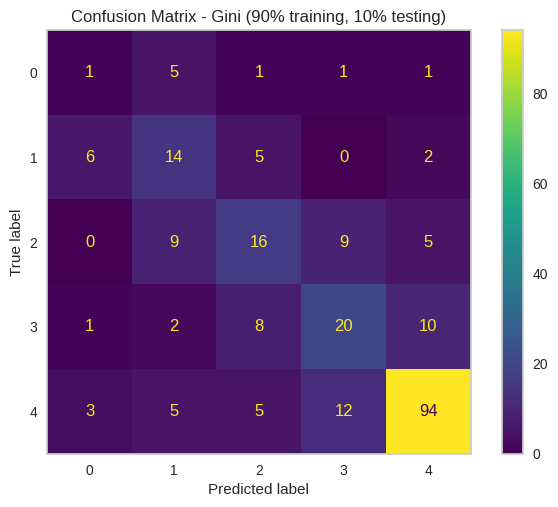

In [146]:
# Partition 1: 90% Training, 10% Testing
# stratify=y keeps the same class proportions in training and testing sets because our classes are imbalanced
X_train_90, X_test_90, y_train_90, y_test_90 = train_test_split(X, y, test_size=0.1, random_state=1, stratify=y)
print("Training set:", X_train_90.shape[0], "records")
print("Testing set:", X_test_90.shape[0], "records")

clf_90 = DecisionTreeClassifier(criterion="gini", random_state=1)
clf_90 = clf_90.fit(X_train_90, y_train_90)
y_pred_90 = clf_90.predict(X_test_90)

acc_90 = metrics.accuracy_score(y_test_90, y_pred_90)
print("Accuracy:", acc_90)

cm_90 = confusion_matrix(y_test_90, y_pred_90)
print(cm_90)

disp = ConfusionMatrixDisplay.from_estimator(clf_90, X_test_90, y_test_90, display_labels=cn)
disp.ax_.grid(False)
plt.title("Confusion Matrix - Gini (90% training, 10% testing)")
plt.show()

## Clustering Findings

The optimal number of clusters is **K = 4**, supported by both the Silhouette score (0.168, the highest) and the Elbow method. The Calinski-Harabasz index favored K = 3, so K = 4 was chosen by majority rule. The cluster centers (standardized values, where 0 means the average student) and Figures 3–5 describe each cluster:


**Cluster centers for K = 4** (standardized values from the cluster centers table in section [6], rounded):

| Cluster | StudyTimeWeekly | Absences | Tutoring | ParentalSupport | Extracurricular | Sports | Music | Volunteering | GPA |
|---|---|---|---|---|---|---|---|---|---|
| 0 | 0.11 | **-0.86** | 0.07 | 0.04 | 0.06 | 0.02 | -0.49 | -0.43 | **0.83** |
| 1 | 0.01 | 0.01 | -0.03 | 0.08 | -0.02 | -0.06 | **2.02** | -0.43 | 0.13 |
| 2 | -0.08 | **0.84** | 0.00 | -0.06 | -0.04 | 0.01 | -0.49 | -0.43 | **-0.86** |
| 3 | -0.06 | -0.03 | -0.12 | -0.03 | -0.02 | -0.01 | 0.03 | **2.31** | -0.02 |

**Figure 3: Clusters by Absences and GPA (K = 4)**

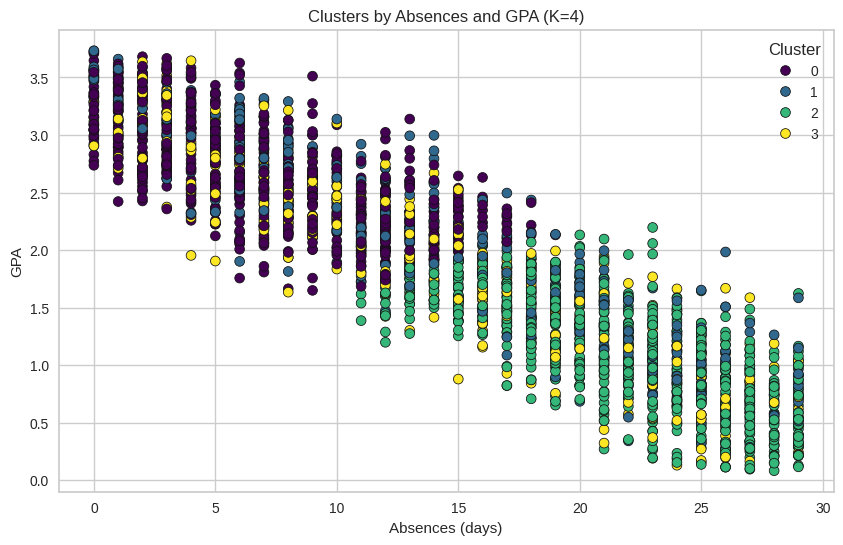

In [147]:
plot_df = features.copy()
plot_df['Cluster'] = labels_4

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Absences', y='GPA', hue='Cluster', data=plot_df, palette='viridis', edgecolor='k')
plt.title('Clusters by Absences and GPA (K=4)')
plt.xlabel('Absences (days)')
plt.ylabel('GPA')
plt.legend(title='Cluster')
plt.show()

**Figure 4: K-Means Clustering Results in PCA space (K = 4)**



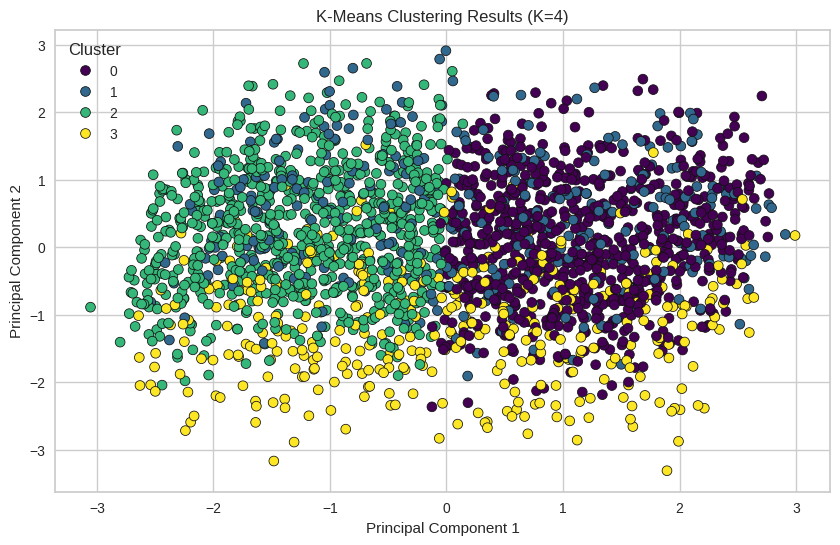

In [148]:
pca_df = pd.DataFrame(pca_features, columns=['PC1', 'PC2'])
pca_df['Cluster'] = labels_4

plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', hue='Cluster', data=pca_df, palette='viridis', edgecolor='k')
plt.title('K-Means Clustering Results (K=4)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

**Figure 5: Silhouette plot (K = 4)**

The average silhouette score is: 0.16806818839938653


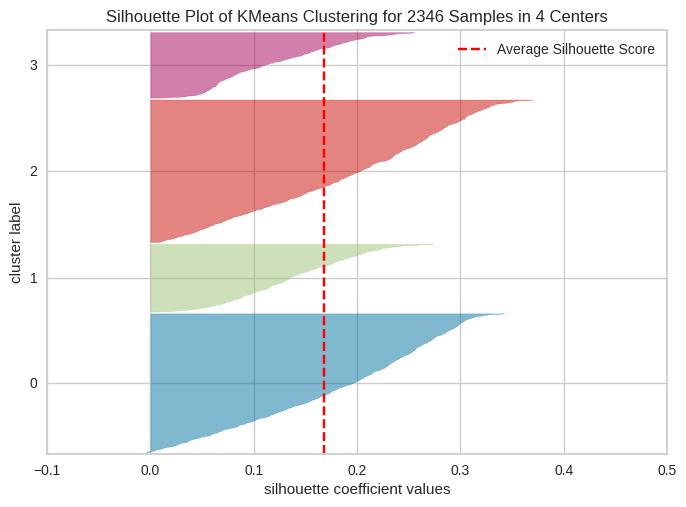

In [149]:

visualizer = SilhouetteVisualizer(KMeans(n_clusters=4, random_state=42, n_init=10), colors='yellowbrick')
visualizer.fit(df_scaled)
print("The average silhouette score is:", visualizer.silhouette_score_)
visualizer.show();

- **Cluster 0: low absences, high GPA.** Absences center = -0.86 and GPA center = +0.83, so these students have fewer absences and a higher GPA than average. They also have slightly above-average weekly study time (+0.11). This is the profile of committed students with regular attendance.
- **Cluster 1: music participants.** Music center = +2.02, meaning the cluster is formed by students who participate in music. Their absences (+0.01) and GPA (+0.13) are close to the average.
- **Cluster 2: high absences, low GPA.** Absences center = +0.84 and GPA center = -0.86, so these students have many more absences and a much lower GPA than average. This is the **at-risk group**. It matches the decision tree, where students with many absences (more than 17.5) are mostly in class 4.
- **Cluster 3: volunteering participants.** Volunteering center = +2.31, meaning the cluster is formed by students who volunteer. Their absences (-0.03) and GPA (-0.02) are close to the average.
- Figure 3 (*Clusters by Absences and GPA*) shows a clear **negative relationship**: students with more absences tend to have a lower GPA. Cluster 0 is in the upper-left area of the plot (low absences, high GPA), and Cluster 2 is in the lower-right area (high absences, low GPA).
- The centers for StudyTimeWeekly, Tutoring, ParentalSupport, Extracurricular and Sports are all close to 0 (between -0.12 and +0.11) in every cluster. These attributes therefore do not define the groups. They explain differences *within* a group, as the decision tree showed.
- The silhouette scores are low (0.164, 0.168 and 0.154) and the clusters overlap in the PCA plot (Figure 4) and the silhouette plot (Figure 5). The clusters should therefore be read as **student profiles** rather than completely separate groups. This is expected because most attributes are binary (0/1).


## Comparing Both Techniques

| | Classification (Decision Tree – Gini) | Clustering (K-means) |
|---|---|---|
| Best model | 90/10 partition, accuracy 61.70% | K = 4, silhouette 0.168 |
| Key attributes | Absences (root), then StudyTimeWeekly and ParentalSupport | Absences and GPA separate Cluster 0 and Cluster 2 |
| Information extracted | Rules that predict each student's grade class | Four student profiles, including an at-risk group |



The two techniques work differently: classification uses the class label and clustering does not. Even so, both reach the **same conclusion**. **Attendance (Absences) is the strongest indicator of academic performance** in this dataset, followed by weekly study time and parental support, while demographic attributes have little effect. Because both methods agree, the results are meaningful and not just a result of one method.

**Solution to the problem:**
1. **Early warning:** the decision tree can be used during the semester. Students with many absences (especially more than 20) are predicted to be in the lowest grade class, so they can be identified before the final exams.
2. **Group interventions:** the at-risk cluster (Cluster 2: high absences, low GPA) helps schools plan support such as attendance follow-up, tutoring sessions and contacting parents.
3. **Study habits:** encouraging regular study time and parental support can move students toward better grade classes within the same attendance level.

**Limitations:**
- The accuracy of about 61% is moderate for a five-class problem.
- The tree is very deep (depth 25, 612 leaves for the 90/10 partition), which indicates overfitting; limiting the tree depth could improve it.
- The model has difficulty predicting class 0 because few students are in that class.
- The clusters overlap (low silhouette scores).

## Discussion based on the Research Paper

Ofori and Dake [3] used the **same Students Performance dataset from Kaggle (2,392 students, 15 attributes)** to predict students' GPA. They developed four deep learning models (LSTM, CNN, RNN and a hybrid LSTM–Transformer) and used Explainable AI techniques (SHAP values and attention weights) to explain which features drive the predictions. Like our clustering step, they standardized the data using z-score normalization (StandardScaler).

- **Agreement on the most important attributes:** Their SHAP analysis found that **absences had the strongest negative effect on performance**, while weekly study time, parental support and tutoring had positive effects. Their correlation analysis also showed a very strong negative relationship between absences and GPA (r = −0.92). This matches our results. Absences is the root of our decision tree (`Absences <= 14.5`), StudyTimeWeekly and ParentalSupport appear in the next levels, and our scatter plot and clusters show the same negative relationship between absences and GPA.
- **Demographic and leisure attributes:** The paper found that gender, age, ethnicity and parental education had minimal impact, and that volunteering, music and sports had relatively low influence. This also agrees with our results. Demographic attributes do not appear in the top levels of our tree, and our music (Cluster 1) and volunteering (Cluster 3) clusters have absences and GPA close to the average, so these activities alone do not separate strong and weak students.
- **Interpretability:** The paper used deep learning models, which are "black boxes", so they needed extra techniques (SHAP and attention) to explain the predictions. In our project, the decision tree is interpretable by itself: its rules (for example, more than 20 absences → class 4) directly show how the classification is made.
- **Difference in task and performance:** The paper predicted the exact GPA (regression), and its best models explained about 74% of the variance in GPA (R² = 0.7427 for LSTM and 0.7378 for the hybrid model). We predicted one of five grade classes (classification) with an accuracy of 61.70%. The results are measured differently, so they cannot be compared directly. Most of our errors are between neighbouring classes, which would be small errors in a regression setting.
- **Clustering:** The paper did not use clustering, so our K-means results add new information: a group of at-risk students (high absences, low GPA) can be discovered from their characteristics without using labels.

Both studies reach the same practical conclusion: **attendance and study habits are the most important factors for academic success**, and these predictions can support early interventions for at-risk students.

Our approach also agrees with Nahar et al. [4], who used decision tree classifiers to predict students' performance early so that weak students can receive counselling before final results. Our decision tree supports the same goal, and its rules on absences and study time are simple for teachers to use.

# [8] References

[1] R. El Kharoua, "Students Performance Dataset," Kaggle, 2024. [Online]. Available: https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset

[2] F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.

[3] E. Ofori and D. K. Dake, "Explainable artificial intelligence in LSTM transformer models for student performance analysis," *Discover Computing*, vol. 28, Art. no. 313, 2025, doi: 10.1007/s10791-025-09814-9.

[4] K. Nahar, B. I. Shova, T. Ria, H. B. Rashid, and A. H. M. S. Islam, "Mining educational data to predict students performance," *Education and Information Technologies*, vol. 26, no. 5, pp. 6051–6067, 2021, doi: 10.1007/s10639-021-10575-3.

[5] J. Han, M. Kamber, and J. Pei, *Data Mining: Concepts and Techniques*, 3rd ed. Waltham, MA, USA: Morgan Kaufmann, 2012.

[6] P. J. Rousseeuw, "Silhouettes: A graphical aid to the interpretation and validation of cluster analysis," *Journal of Computational and Applied Mathematics*, vol. 20, pp. 53–65, 1987, doi: 10.1016/0377-0427(87)90125-7.

[7] T. Caliński and J. Harabasz, "A dendrite method for cluster analysis," *Communications in Statistics*, vol. 3, no. 1, pp. 1–27, 1974, doi: 10.1080/03610927408827101.

[8] B. Bengfort and R. Bilbro, "Yellowbrick: Visualizing the scikit-learn model selection process," *Journal of Open Source Software*, vol. 4, no. 35, Art. no. 1075, 2019, doi: 10.21105/joss.01075.